# Setup

In [1]:
!nvidia-smi

Mon Oct 26 12:36:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             42W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')


import os
DRIVE_ROOT = '/content/drive/MyDrive/stylessp'
CKPT_DIR   = f'{DRIVE_ROOT}/checkpoints'
HF_CACHE = '/content/hf_cache'
REPO_DIR   = '/content/StyleSSP'

for d in [DRIVE_ROOT, CKPT_DIR, HF_CACHE]:
    os.makedirs(d, exist_ok=True)


os.environ['HF_HOME'] = HF_CACHE

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


fresh copy for every session

In [3]:

!rm -rf {REPO_DIR}
!git clone https://github.com/Michael-Boat-2/StyleSSP {REPO_DIR}
%cd {REPO_DIR}
!git log --oneline -1


Cloning into '/content/StyleSSP'...
remote: Enumerating objects: 142, done.
remote: Counting objects: 100% (77/77), done.
remote: Compressing objects: 100% (50/50), done.
remote: Total 142 (delta 38), reused 53 (delta 23), pack-reused 65 (from 1)
Receiving objects: 100% (142/142), 3.35 MiB | 32.32 MiB/s, done.
Resolving deltas: 100% (59/59), done.
/content/StyleSSP
1f2d6d2 (HEAD -> main, origin/main, origin/HEAD) Update fm_paper.py


Installing Pinned Libraries

In [4]:
!pip install -q uv
!uv venv /content/venv --python 3.9
!uv pip install --python /content/venv/bin/python -r requirements.txt setuptools==69.5.1 datasets==2.21.0
!uv pip install --python /content/venv/bin/python git+https://github.com/openai/CLIP.git

!/content/venv/bin/python -c "import torch, diffusers, transformers; print('torch', torch.__version__, '| cuda', torch.cuda.is_available(), '| diffusers', diffusers.__version__, '| transformers', transformers.__version__)"

Using CPython 3.9.25
Creating virtual environment at: /content/venv
? A virtual environment already exists at `/content/venv`. Do you want to replace it? [y/n] › yes

✔ A virtual environment already exists at `/content/venv`. Do you want to replace it? · no
error: Failed to create virtual environment
  cause: A virtual environment already exists at: /content/venv

hint: Use the `--clear` flag or set `UV_VENV_CLEAR=1` to replace the existing virtual environment
Using Python 3.9.25 environment at: /content/venv
Checked 79 packages in 8ms
Using Python 3.9.25 environment at: /content/venv
Resolved 31 packages in 270ms
Checked 31 packages in 0.39ms
torch 2.3.0+cu121 | cuda True | diffusers 0.30.0 | transformers 4.44.0


In [ ]:

!/content/venv/bin/python repro/sample_data.py --out {DRIVE_ROOT}/data --cache {DRIVE_ROOT}/data/cache


Saved 10 content and 10 style images.


Downloading Checkpoints

In [5]:
from huggingface_hub import snapshot_download, hf_hub_download
import os

def have(path):
    return os.path.exists(path) and os.path.getsize(path) > 0



# IP-Adapter:  SDXL weights file for style injection during sampling
if not have(f'{CKPT_DIR}/IP-Adapter/sdxl_models/ip-adapter_sdxl_vit-h.safetensors'):
    snapshot_download('h94/IP-Adapter', local_dir=f'{CKPT_DIR}/IP-Adapter',
                      allow_patterns=['sdxl_models/ip-adapter_sdxl_vit-h.safetensors'])

# ControlNets (control_type = 'tile_canny' in config.py) : content preservation during sampling
if not os.path.exists(f'{CKPT_DIR}/controlnet-tile-sdxl-1.0/config.json'):
    snapshot_download('xinsir/controlnet-tile-sdxl-1.0', local_dir=f'{CKPT_DIR}/controlnet-tile-sdxl-1.0',
                      allow_patterns=['config.json', '*.safetensors'])

if not os.path.exists(f'{CKPT_DIR}/MistoLine/config.json'):
    snapshot_download('TheMistoAI/MistoLine', local_dir=f'{CKPT_DIR}/MistoLine',
                      allow_patterns=['config.json', '*.fp16.safetensors'])

# IP-Adapter-Instruct: the content/style extractor behind negative guidance
if not have(f'{CKPT_DIR}/models/ip-adapter-instruct-sdxl.bin'):
    hf_hub_download('CiaraRowles/IP-Adapter-Instruct', 'ip-adapter-instruct-sdxl.bin',
                    local_dir=f'{CKPT_DIR}/models')


!mkdir -p /content/checkpoints && cp -rn {DRIVE_ROOT}/checkpoints/. /content/checkpoints/
!ln -sfn /content/checkpoints {REPO_DIR}/checkpoints
!du -sh /content/checkpoints/*

cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
2.4G	/content/checkpoints/controlnet-tile-sdxl-1.0
667M	/content/checkpoints/IP-Adapter
2.4G	/content/checkpoints/MistoLine
2.0G	/content/checkpoints/models


In [6]:
!ls /content/venv/bin/python /content/checkpoints /content/drive/MyDrive/stylessp

/content/venv/bin/python

/content/checkpoints:
controlnet-tile-sdxl-1.0  IP-Adapter  MistoLine  models

/content/drive/MyDrive/stylessp:
checkpoints	  hf_cache	    ours_content_style.png
colab_freeze.txt  metrics.csv	    runs
data		  ours_c07_s00.png  test_images


In [7]:
# run fm from paper ablatation
!/content/venv/bin/python repro/run_ablation.py --data {DRIVE_ROOT}/data --out {DRIVE_ROOT}/runs \
    --seed 1234 --phase sample --configs fm_paper

100 pairs x 5 configs, seed 1234
Phase B: 100 of 100 pairs still to sample

[load] phase_B_models: 8.6s
True

[sample_fm_paper] c00_s00: 12.8s
True

[sample_fm_paper] c00_s01: 11.9s
True

[sample_fm_paper] c00_s02: 11.8s
True

[sample_fm_paper] c00_s03: 11.6s
True

[sample_fm_paper] c00_s04: 11.7s
True

[sample_fm_paper] c00_s05: 11.8s
True

[sample_fm_paper] c00_s06: 11.9s
True

[sample_fm_paper] c00_s07: 11.7s
True

[sample_fm_paper] c00_s08: 11.6s
True

[sample_fm_paper] c00_s09: 11.8s
True

[sample_fm_paper] c01_s00: 11.8s
True

[sample_fm_paper] c01_s01: 11.7s
True

[sample_fm_paper] c01_s02: 11.7s
True

[sample_fm_paper] c01_s03: 11.4s
True

[sample_fm_paper] c01_s04: 11.7s
True

[sample_fm_paper] c01_s05: 11.7s
True

[sample_fm_paper] c01_s06: 11.9s
True

[sample_fm_paper] c01_s07: 11.7s
True

[sample_fm_paper] c01_s08: 11.7s
True

[sample_fm_paper] c01_s09: 11.7s
True

[sample_fm_paper] c02_s00: 11.8s
True

[sample_fm_paper] c02_s01: 11.8s
True

[sample_fm_paper] c02_s02: 11.8s

In [8]:
# evaluate fm from paper
!/content/venv/bin/python repro/eval.py --runs {DRIVE_ROOT}/runs --data {DRIVE_ROOT}/data

Evaluating seed1234 / baseline on 100 images...
  ArtFID 43.134  FID 28.655  LPIPS 0.4545
Evaluating seed1234 / fm on 100 images...
  ArtFID 51.262  FID 32.483  LPIPS 0.5310
Evaluating seed1234 / ng on 100 images...
  ArtFID 43.184  FID 28.675  LPIPS 0.4552
Evaluating seed1234 / full on 100 images...
  ArtFID 51.333  FID 32.532  LPIPS 0.5309
Evaluating seed1234 / fm_paper on 100 images...
  ArtFID 46.117  FID 30.013  LPIPS 0.4870
Evaluating seed42 / baseline on 100 images...
  ArtFID 43.105  FID 28.679  LPIPS 0.4524
Evaluating seed42 / fm on 100 images...
  ArtFID 51.518  FID 32.507  LPIPS 0.5375
Evaluating seed42 / ng on 100 images...
  ArtFID 43.119  FID 28.670  LPIPS 0.4533
Evaluating seed42 / full on 100 images...
  ArtFID 51.529  FID 32.517  LPIPS 0.5374
Wrote 9 rows to /content/StyleSSP/results/metrics.csv


In [9]:
!cp {REPO_DIR}/results/metrics.csv {DRIVE_ROOT}/metrics.csv
!cat {REPO_DIR}/results/metrics.csv

seed,config,n_images,artfid,fid,lpips,lpips_gray
1234,baseline,100,43.13380813598633,28.65520868682524,0.45451033115386963,0.3334183394908905
1234,fm,100,51.26200866699219,32.48326114857719,0.5309742093086243,0.4020991027355194
1234,ng,100,43.18431091308594,28.675479461781883,0.45521867275238037,0.3342365324497223
1234,full,100,51.332698822021484,32.53204740481548,0.5308550000190735,0.40187937021255493
1234,fm_paper,100,46.11678695678711,30.01325883393227,0.4870024025440216,0.35346895456314087
42,baseline,100,43.104835510253906,28.678686917398558,0.4523835778236389,0.32942524552345276
42,fm,100,51.518043518066406,32.50732158936295,0.5375160574913025,0.40825116634368896
42,ng,100,43.11870193481445,28.670412183051827,0.45325595140457153,0.33047348260879517
42,full,100,51.52924346923828,32.51652093841463,0.5374282002449036,0.4081757366657257


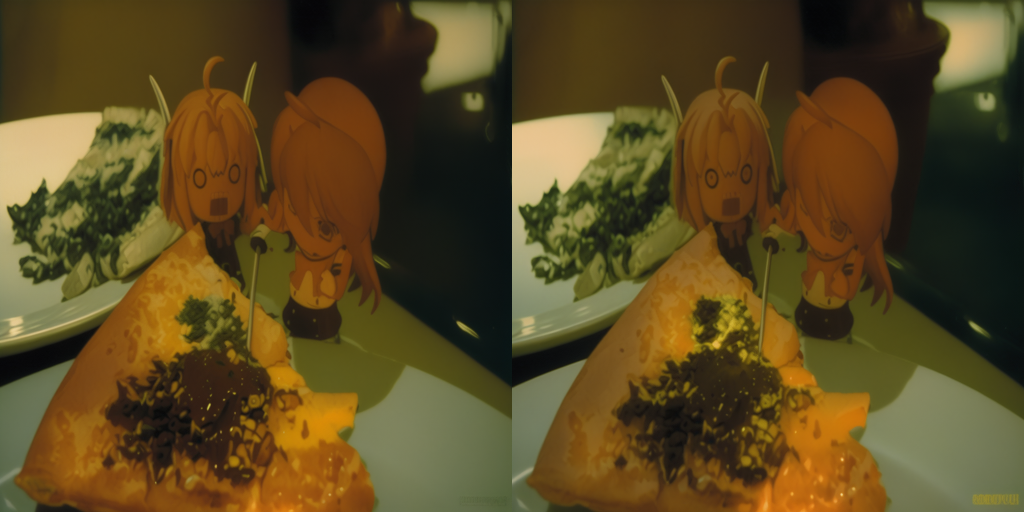

a white plate with a slice of pizza on it


In [10]:
from PIL import Image
from IPython.display import display
a = Image.open(f'{DRIVE_ROOT}/ours_c07_s00.png').resize((512, 512))
b = Image.open(f'{DRIVE_ROOT}/runs/seed1234/images/full/c07_s00.png').resize((512, 512))
canvas = Image.new('RGB', (1024, 512)); canvas.paste(a, (0, 0)); canvas.paste(b, (512, 0))
display(canvas)
import torch; print(torch.load(f'{DRIVE_ROOT}/runs/seed1234/latents/c07_s00.pt')['prompt'])

In [11]:
!pip install -q lpips

In [12]:
import lpips, torch, numpy as np
from PIL import Image
loss = lpips.LPIPS(net='alex')
def t(p): return torch.tensor(np.asarray(Image.open(p).convert('RGB').resize((512, 512)))).permute(2, 0, 1)[None].float() / 127.5 - 1
c = t(f'{DRIVE_ROOT}/data/content/c00.jpg')
for cfg in ['baseline', 'fm']:
    print(cfg, loss(t(f'{DRIVE_ROOT}/runs/seed1234/images/{cfg}/c00_s00.png'), c).item())

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
baseline 0.3828147053718567
fm 0.5329859852790833


In [ ]:
%%time
!/content/venv/bin/python repro/run_ablation.py --data {DRIVE_ROOT}/data --out {DRIVE_ROOT}/runs

100 pairs x 4 configs, seed 1234
Phase A: 98 of 100 pairs still to invert
Some kwargs in processor config are unused and will not have any effect: num_query_tokens. 

Keyword arguments {'safety_checker': None} are not expected by StableDiffusionXLPipelineExtraCFG and will be ignored.

dict_keys(['latents', 'proj_in.weight', 'proj_in.bias', 'proj_new_input.weight', 'proj_new_input.bias', 'proj_prompt_input.weight', 'proj_prompt_input.bias', 'proj_out.weight', 'proj_out.bias', 'norm_out.weight', 'norm_out.bias', 'layers.0.0.norm1.weight', 'layers.0.0.norm1.bias', 'layers.0.0.norm2.weight', 'layers.0.0.norm2.bias', 'layers.0.0.to_q.weight', 'layers.0.0.to_kv.weight', 'layers.0.0.to_out.weight', 'layers.0.1.0.weight', 'layers.0.1.0.bias', 'layers.0.1.1.weight', 'layers.0.1.3.weight', 'layers.1.0.norm1.weight', 'layers.1.0.norm1.bias', 'layers.1.0.norm2.weight', 'layers.1.0.norm2.bias', 'layers.1.0.to_q.weight', 'layers.1.0.to_kv.weight', 'layers.1.0.to_out.weight', 'layers.1.1.0.weight', '

In [6]:
!/content/venv/bin/python repro/eval.py --runs {DRIVE_ROOT}/runs --data {DRIVE_ROOT}/data
!cp {REPO_DIR}/results/metrics.csv {DRIVE_ROOT}/metrics.csv
!cat {REPO_DIR}/results/metrics.csv

Evaluating seed1234 / baseline on 100 images...
  ArtFID 43.134  FID 28.655  LPIPS 0.4545
Evaluating seed1234 / fm on 100 images...
  ArtFID 51.262  FID 32.483  LPIPS 0.5310
Evaluating seed1234 / ng on 100 images...
  ArtFID 43.184  FID 28.675  LPIPS 0.4552
Evaluating seed1234 / full on 100 images...
  ArtFID 51.333  FID 32.532  LPIPS 0.5309
Evaluating seed42 / baseline on 100 images...
  ArtFID 43.105  FID 28.679  LPIPS 0.4524
Evaluating seed42 / fm on 100 images...
  ArtFID 51.518  FID 32.507  LPIPS 0.5375
Evaluating seed42 / ng on 100 images...
  ArtFID 43.119  FID 28.670  LPIPS 0.4533
Evaluating seed42 / full on 100 images...
  ArtFID 51.529  FID 32.517  LPIPS 0.5374
Wrote 8 rows to /content/StyleSSP/results/metrics.csv
seed,config,n_images,artfid,fid,lpips,lpips_gray
1234,baseline,100,43.13380813598633,28.655208678741033,0.45451033115386963,0.3334183394908905
1234,fm,100,51.26200866699219,32.48326113518348,0.5309742093086243,0.4020991027355194
1234,ng,100,43.18431091308594,28.6754

In [ ]:
import os
d = f'{DRIVE_ROOT}/runs/seed1234'
print('latents:', len(os.listdir(f'{d}/latents')))
for c in ['baseline', 'fm', 'ng', 'full']:
    print(c, len(os.listdir(f'{d}/images/{c}')))

latents: 100
baseline 100
fm 100
ng 100
full 100


In [ ]:
!/content/venv/bin/python repro/run_ablation.py --data {DRIVE_ROOT}/data --out {DRIVE_ROOT}/runs --seed 42

100 pairs x 4 configs, seed 42
Phase A: 100 of 100 pairs still to invert
Some kwargs in processor config are unused and will not have any effect: num_query_tokens. 

Keyword arguments {'safety_checker': None} are not expected by StableDiffusionXLPipelineExtraCFG and will be ignored.

dict_keys(['latents', 'proj_in.weight', 'proj_in.bias', 'proj_new_input.weight', 'proj_new_input.bias', 'proj_prompt_input.weight', 'proj_prompt_input.bias', 'proj_out.weight', 'proj_out.bias', 'norm_out.weight', 'norm_out.bias', 'layers.0.0.norm1.weight', 'layers.0.0.norm1.bias', 'layers.0.0.norm2.weight', 'layers.0.0.norm2.bias', 'layers.0.0.to_q.weight', 'layers.0.0.to_kv.weight', 'layers.0.0.to_out.weight', 'layers.0.1.0.weight', 'layers.0.1.0.bias', 'layers.0.1.1.weight', 'layers.0.1.3.weight', 'layers.1.0.norm1.weight', 'layers.1.0.norm1.bias', 'layers.1.0.norm2.weight', 'layers.1.0.norm2.bias', 'layers.1.0.to_q.weight', 'layers.1.0.to_kv.weight', 'layers.1.0.to_out.weight', 'layers.1.1.0.weight', 'l

In [ ]:
#negatuve guidance effect, sanity check

import numpy as np
from PIL import Image
d = f'{DRIVE_ROOT}/runs/seed1234/images'
for name in ['c00_s00', 'c00_s01']:
    a = np.asarray(Image.open(f'{d}/baseline/{name}.png'), dtype=float)
    for cfg in ['fm', 'ng', 'full']:
        b = np.asarray(Image.open(f'{d}/{cfg}/{name}.png'), dtype=float)
        print(name, cfg, 'mean abs diff vs baseline:', round(np.abs(a - b).mean(), 2))

c00_s00 fm mean abs diff vs baseline: 27.56
c00_s00 ng mean abs diff vs baseline: 1.77
c00_s00 full mean abs diff vs baseline: 27.54
c00_s01 fm mean abs diff vs baseline: 47.46
c00_s01 ng mean abs diff vs baseline: 1.54
c00_s01 full mean abs diff vs baseline: 47.58


Recording the used environment for the reproduction

In [ ]:
!mkdir -p {REPO_DIR}/repro/env
!/content/venv/bin/python --version > {REPO_DIR}/repro/env/colab_freeze.txt
!uv pip freeze --python /content/venv/bin/python >> {REPO_DIR}/repro/env/colab_freeze.txt
!cp {REPO_DIR}/repro/env/colab_freeze.txt {DRIVE_ROOT}/colab_freeze.txt
!head -5 {DRIVE_ROOT}/colab_freeze.txt


Using Python 3.9.25 environment at: /content/venv


In [ ]:
# test pair for our config

CONTENT = f'{DRIVE_ROOT}/data/content/c07.jpg'
STYLE   = f'{DRIVE_ROOT}/data/style/s09.jpg'

!sed -i "s|style_image_dir = .*|style_image_dir = '{STYLE}'|" src/config.py
!sed -i "s|content_image_dir = .*|content_image_dir = '{CONTENT}'|" src/config.py
!grep -n "image_dir" src/config.py

66:    style_image_dir = '/content/drive/MyDrive/stylessp/data/style/s00.jpg'
67:    content_image_dir = '/content/drive/MyDrive/stylessp/data/content/c07.jpg'


In [ ]:
%%time
!/content/venv/bin/python infer_style.py

Some kwargs in processor config are unused and will not have any effect: num_query_tokens. 

Keyword arguments {'safety_checker': None} are not expected by StableDiffusionXLPipelineExtraCFG and will be ignored.

dict_keys(['latents', 'proj_in.weight', 'proj_in.bias', 'proj_new_input.weight', 'proj_new_input.bias', 'proj_prompt_input.weight', 'proj_prompt_input.bias', 'proj_out.weight', 'proj_out.bias', 'norm_out.weight', 'norm_out.bias', 'layers.0.0.norm1.weight', 'layers.0.0.norm1.bias', 'layers.0.0.norm2.weight', 'layers.0.0.norm2.bias', 'layers.0.0.to_q.weight', 'layers.0.0.to_kv.weight', 'layers.0.0.to_out.weight', 'layers.0.1.0.weight', 'layers.0.1.0.bias', 'layers.0.1.1.weight', 'layers.0.1.3.weight', 'layers.1.0.norm1.weight', 'layers.1.0.norm1.bias', 'layers.1.0.norm2.weight', 'layers.1.0.norm2.bias', 'layers.1.0.to_q.weight', 'layers.1.0.to_kv.weight', 'layers.1.0.to_out.weight', 'layers.1.1.0.weight', 'layers.1.1.0.bias', 'layers.1.1.1.weight', 'layers.1.1.3.weight', 'layers.

results/ours_c07_s00.png


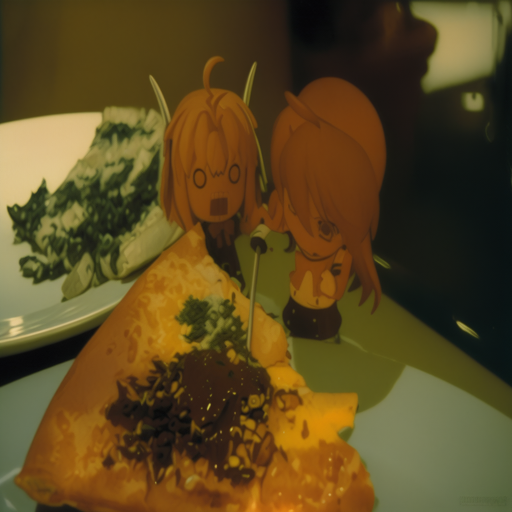

In [ ]:
from IPython.display import display
from PIL import Image
import glob, shutil

for p in sorted(glob.glob('results/*.png')):
    print(p)
    display(Image.open(p).resize((512, 512)))
    shutil.copy(p, f'{DRIVE_ROOT}/')

In [15]:
!git pull

remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 4 (delta 3), reused 4 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 373 bytes | 373.00 KiB/s, done.
From https://github.com/Michael-Boat-2/StyleSSP
   7d636c3..9a2b5ce  main       -> origin/main
Updating 7d636c3..9a2b5ce
Fast-forward
 repro/make_figures.py | 2 +-
 1 file changed, 1 insertion(+), 1 deletion(-)


In [16]:
!git pull


Already up to date.


In [17]:
!python repro/make_figures.py --runs {DRIVE_ROOT}/runs --data {DRIVE_ROOT}/data
!cp {REPO_DIR}/results/table2.tex {REPO_DIR}/results/qualitative_grid.png {DRIVE_ROOT}/

\begin{tabular}{l|ccc|ccc}
\hline
 & \multicolumn{3}{c|}{Paper (800 images)} & \multicolumn{3}{c}{Ours (100 images, mean $\pm$ half-range over seeds)} \\
Config & ArtFID & FID & LPIPS & ArtFID & FID & LPIPS \\
\hline
baseline & 26.68 & 16.20 & 0.5509 & 43.12 $\pm$ 0.01 & 28.67 $\pm$ 0.01 & 0.4534 $\pm$ 0.0011 \\
fm & 24.11 & 15.10 & 0.4973 & 51.39 $\pm$ 0.13 & 32.50 $\pm$ 0.01 & 0.5342 $\pm$ 0.0033 \\
ng & 26.54 & 16.13 & 0.5496 & 43.15 $\pm$ 0.03 & 28.67 $\pm$ 0.00 & 0.4542 $\pm$ 0.0010 \\
full & 21.50 & 13.45 & 0.4881 & 51.43 $\pm$ 0.10 & 32.52 $\pm$ 0.01 & 0.5341 $\pm$ 0.0033 \\
fm-paper & -- & -- & -- & 46.12 & 30.01 & 0.4870 \\
\hline
\end{tabular}
Saved grid with columns ['content', 'style', 'baseline', 'fm', 'ng', 'full', 'fm_paper'] to /content/StyleSSP/results/qualitative_grid.png
